# Персональные top-10 рекомендации
**Автор: Габидулин Андрей. Домашнее задание 1.**

Amazon Reviews 2018, Musical Instruments. Пять самостоятельных реализаций: item-kNN, iALS, EASE, FM, ALS с кастомным таргетом.

Запуск из `hw1/`: Python 3.12, `python -m pip install -r requirements.txt`, затем `python run_notebook.py`. Первый запуск скачивает два официальных gzip-файла в `.cache/raw/`; последующие проверяют SHA256. Нужны интернет, CPU и около 4 ГБ свободной RAM. Данные не включены в репозиторий. Ноутбук выполняет весь эксперимент заново; отдельный сервер Jupyter не нужен.

In [1]:
import os
for key in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'VECLIB_MAXIMUM_THREADS'):
    os.environ[key] = '1'
import json
import platform
from pathlib import Path
from time import perf_counter
import importlib.metadata
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits

if not Path('models').is_dir():
    os.chdir('hw1')
from data import SOURCE, SOURCES, SHA256, download_data, read_reviews, read_metadata, prepare_data, interaction_matrix
from evaluation import evaluation_users
from experiment import run_validation, run_test, paired_bootstrap

CONFIG = json.loads(Path('config.json').read_text())
random.seed(CONFIG['seed'])
np.random.seed(CONFIG['seed'])
torch.manual_seed(CONFIG['seed'])
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
threads = threadpool_limits(limits=1)
START = perf_counter()
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': 0.2})
print(platform.platform(), '| logical CPUs:', os.cpu_count(), '| compute: CPU, one thread')
display(pd.Series({p: importlib.metadata.version(p) for p in
                   ['numpy', 'scipy', 'pandas', 'torch', 'matplotlib', 'nbclient']}, name='version'))
print(json.dumps(CONFIG, indent=2))

Matplotlib is building the font cache; this may take a moment.


macOS-15.6.1-arm64-arm-64bit | logical CPUs: 12 | compute: CPU, one thread


numpy          2.3.5
scipy         1.18.1
pandas         2.2.3
torch          2.8.0
matplotlib    3.10.6
nbclient      0.10.2
Name: version, dtype: object

{
  "seed": 42,
  "primary_metric": "NDCG@10",
  "k": 10,
  "max_items": 6000,
  "min_train_history": 3,
  "knn": {
    "neighbors": [
      50,
      150
    ],
    "shrinkage": [
      10,
      50
    ]
  },
  "ials": {
    "factors": [
      16,
      32
    ],
    "alpha": [
      10,
      40
    ],
    "regularization": [
      0.1,
      1
    ]
  },
  "ease": {
    "regularization": [
      50,
      200,
      1000
    ]
  },
  "fm": {
    "factors": [
      16,
      32
    ],
    "regularization": [
      1e-05,
      0.0001
    ]
  },
  "custom_als": {
    "beta": [
      0.5,
      1
    ],
    "half_life_days": [
      180,
      730
    ]
  },
  "als_iterations": 10,
  "fm_epochs": 12,
  "fm_learning_rate": 0.01,
  "fm_negative_ratio": 3,
  "fm_batch_size": 4096
}


## 1. Данные и задача
[Первоисточник Amazon Review Data (2018)](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/), Jianmo Ni, Julian McAuley. Берём **Musical Instruments 5-core** (231 392 отзыва до очистки) и метаданные этой категории. Это отзывы о музыкальных инструментах и аксессуарах, не просмотры и не журнал всех покупок.

| Поле | Смысл |
|---|---|
| `reviewerID`, `asin` | Пользователь, товар |
| `overall` | Оценка от 1 до 5 |
| `unixReviewTime` | Время отзыва, UTC |
| `title`, `brand`, `category` | Название, бренд, иерархия категории товара |

Рекомендуем ещё не оценённые товары. **Релевантность: будущая оценка ≥ 4**, одинаковая для всех моделей. Оценки 1–3 не считаем релевантными. Отсутствие отзыва не означает, что товар не понравился. Тексты отзывов и персональные профили не используются.

In [2]:
loaded_at = perf_counter()
print(SOURCE)
for field, url in SOURCES.items():
    print(field, url)
paths = download_data()
reviews, diagnostics = read_reviews(paths['reviews'])
metadata = read_metadata(paths['metadata'], reviews.item_id.unique())
bundle = prepare_data(reviews, metadata, CONFIG['max_items'], CONFIG['min_train_history'])
parts, items, shape = bundle['parts'], bundle['items'], bundle['shape']
print('Load/prepare seconds:', round(perf_counter() - loaded_at, 2))
display(pd.Series(diagnostics, name='value').to_frame())
display(pd.DataFrame([
    ['raw reviews', diagnostics['raw_rows'], reviews.user_id.nunique(), reviews.item_id.nunique()],
    ['deduplicated', len(reviews), reviews.user_id.nunique(), reviews.item_id.nunique()],
    ['selected', len(bundle['frame']), *shape],
], columns=['stage', 'interactions', 'users', 'items']))
print('Filtered metadata rows:', len(metadata))

https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/
reviews https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFilesSmall/Musical_Instruments_5.json.gz
metadata https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/metaFiles2/meta_Musical_Instruments.json.gz
reviews: 37.5 MiB; SHA256 e3ae8a3f0d70bf63242a49539a8847d30216a3aa2938c049c7f43d0473fef1bc


metadata: 165.2 MiB; SHA256 8e3f0dbe4c6c1aa5b32d350aa26072232beb6160ff3c5dadb44bca2c473a8b41


Load/prepare seconds: 4.52


,value
raw_rows,231392
missing,"{'user_id': 0, 'item_id': 0, 'rating': 0, 'tim..."
exact_duplicates,10295
duplicate_pairs,12236
invalid_rows,0
deduplicated_rows,219156


,stage,interactions,users,items
0,raw reviews,231392,27530,10620
1,deduplicated,219156,27530,10620
2,selected,149744,20159,6000


Filtered metadata rows: 10611


## 2. Очистка и EDA
Удаляем пропуски/некорректные значения, затем повторные пары пользователь–товар, оставляя **первый** отзыв. Поздняя редакция отзыва не заменяет прошлую оценку.

Границы времени — глобальные 70-й и 85-й процентили времени после дедупликации; одинаковые timestamps остаются в одной части. Из train берём 6000 наиболее частых товаров (при равенстве — ASIN). Итеративно оставляем пользователей и товары с ≥ 3 взаимодействиями в train. Этот каталог и список пользователей замораживаются. Ограничение каталога делает плотный EASE посильным CPU; будущая популярность в отборе не участвует. Случайной подвыборки нет, все сортировки детерминированы.

Sparsity selected: 99.876198%
Sparsity train: 99.890464%


,user activity,item popularity
count,20159.000000,6000.000000
mean,7.428146,24.957333
std,5.535648,60.607734
min,3.000000,3.000000
25%,5.000000,8.000000
50%,6.000000,12.000000
75%,8.000000,23.000000
max,168.000000,1383.000000


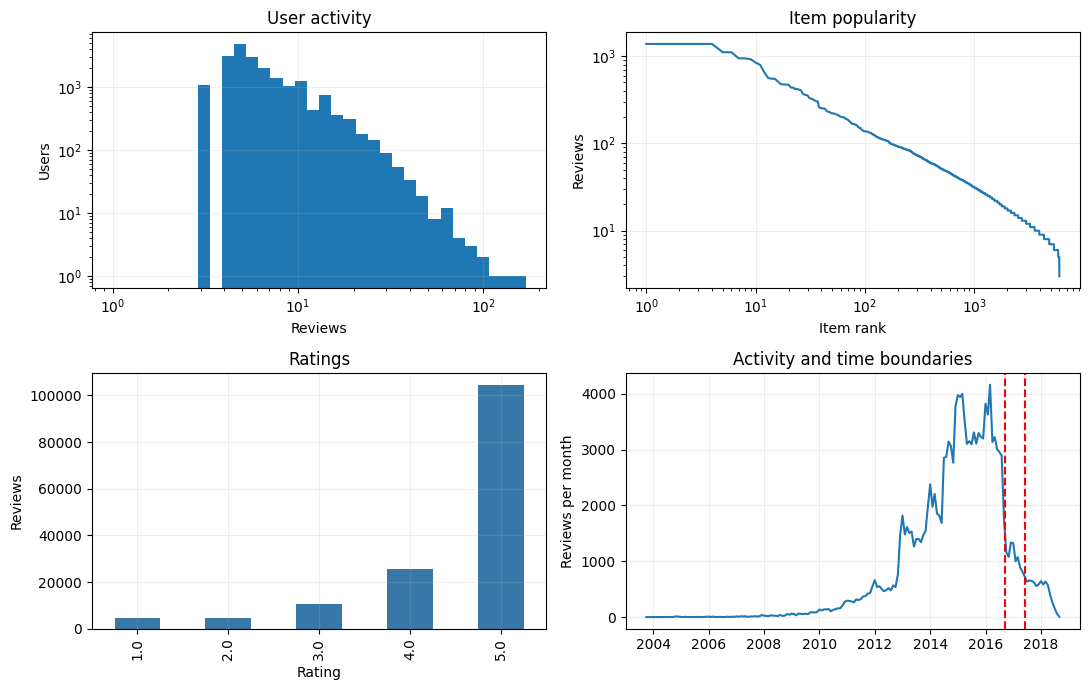

In [3]:
selected = bundle['frame']
activity = selected.groupby('user_id').size()
popularity = selected.groupby('item_id').size().sort_values(ascending=False)
train_activity = parts['train'].groupby('user_id').size()
print(f'Sparsity selected: {1-len(selected)/(shape[0]*shape[1]):.6%}')
print(f'Sparsity train: {1-len(parts["train"])/(shape[0]*shape[1]):.6%}')
display(pd.DataFrame({'user activity': activity.describe(), 'item popularity': popularity.describe()}))
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
axes[0,0].hist(activity, bins=np.geomspace(1, activity.max()+1, 35))
axes[0,0].set(xscale='log', yscale='log', title='User activity', xlabel='Reviews', ylabel='Users')
axes[0,1].plot(np.arange(1, len(popularity)+1), popularity.to_numpy())
axes[0,1].set(xscale='log', yscale='log', title='Item popularity', xlabel='Item rank', ylabel='Reviews')
selected.rating.value_counts().sort_index().plot.bar(ax=axes[1,0], color='#3878a8')
axes[1,0].set(title='Ratings', xlabel='Rating', ylabel='Reviews')
monthly = selected.assign(month=pd.to_datetime(selected.timestamp, unit='s', utc=True).dt.strftime('%Y-%m')).groupby('month').size()
axes[1,1].plot(pd.to_datetime(monthly.index), monthly.values)
for cutoff in bundle['cuts']:
    axes[1,1].axvline(pd.to_datetime(cutoff, unit='s'), color='red', linestyle='--')
axes[1,1].set(title='Activity and time boundaries', ylabel='Reviews per month')
fig.tight_layout()
plt.show()

,missing,unique_nonmissing
title,5,5975
brand,41,1091
category,153,353


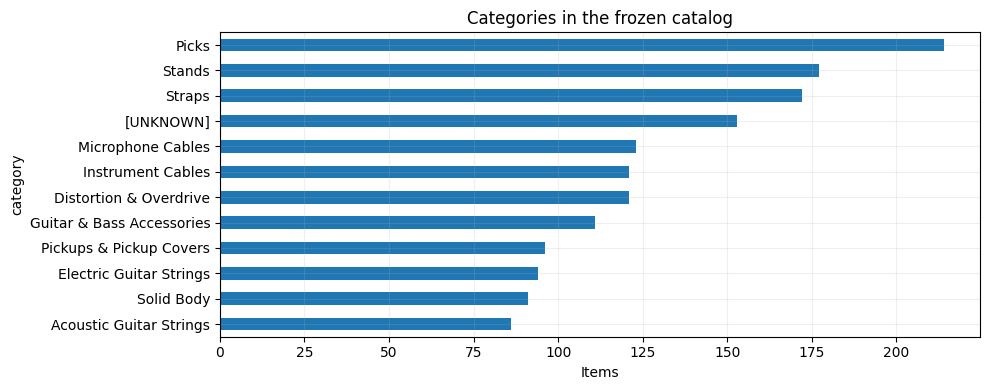

In [4]:
metadata_summary = pd.DataFrame({
    'missing': [int(items.title.eq('').sum()), int(items.brand.eq('[UNKNOWN]').sum()),
                int(items.category.eq('[UNKNOWN]').sum())],
    'unique_nonmissing': [items.loc[items.title.ne(''), 'title'].nunique(),
                         items.loc[items.brand.ne('[UNKNOWN]'), 'brand'].nunique(),
                         items.loc[items.category.ne('[UNKNOWN]'), 'category'].nunique()]
}, index=['title', 'brand', 'category'])
display(metadata_summary)
items.category.value_counts().head(12).sort_values().plot.barh(figsize=(10,4), title='Categories in the frozen catalog')
plt.xlabel('Items')
plt.tight_layout()
plt.show()

Медиана — 6 отзывов на пользователя и 12 на товар; разреженность train — 99.8905%. Популярность имеет длинный хвост. Из 6000 карточек отсутствуют 5 названий, 41 бренд, 153 категории.

FM использует one-hot **user ID, item ID, бренд, последнюю категорию иерархии**. Бренд связывает товары производителя, категория — товары одного назначения. Словари строятся только по замороженному train-каталогу; пропуски получают `[UNKNOWN]`. Названия используются только для просмотра рекомендаций.

Предполагаем, что бренд/категория карточки известны при рекомендации. Дамп метаданных не версионирован во времени: полную историческую доступность подтвердить нельзя. Цена, sales rank, агрегаты отзывов, `also_buy` и тексты будущих отзывов не используются.

## 3. Протокол
Train предшествует validation, validation — test. Новые пользователи и товары исключаются из обеих отложенных частей: здесь оценивается **warm-start**. Объём исключений показан ниже. После выбора настроек переобучаем на train + validation; каталог и ID остаются прежними.

Кандидаты — все 6000 товаров каталога, кроме **любых** уже оценённых пользователем, независимо от оценки. Негативы для оценки не семплируются. Пользователь оценивается, если в доступной истории ≥ 2 положительных отзывов и в отложенной части ≥ 1 релевантного товара. В каждой части все модели получают один список пользователей и одинаковые кандидаты. Списки validation/test могут различаться из-за активности; test не определяет пользователей validation.

**Основная метрика выбрана до подбора: NDCG@10** — учитывает позицию релевантного товара. Дополнительно Recall@10 — доля найденных релевантных товаров; Coverage@10 — доля каталога, попавшая хотя бы в один top-10. Метрики усредняются по пользователям:

$$Recall@10=\frac{|R_u\cap Top10_u|}{|R_u|},\quad NDCG@10=\frac{\sum_{j=1}^{10} rel_{uj}/\log_2(j+1)}{\sum_{j=1}^{\min(10,|R_u|)}1/\log_2(j+1)}.$$

При одинаковых score порядок задаёт ASIN (фиксированный индекс). Каждый пользователь получает ровно 10 разных неизвестных товаров.

In [5]:
rows=[]
raw_split = np.select([reviews.timestamp < bundle['cuts'][0], reviews.timestamp < bundle['cuts'][1]],
                      ['train', 'validation'], default='test')
for name, part in parts.items():
    rows.append({'split': name, 'before_warm_filter': int((raw_split == name).sum()),
                 'interactions': len(part), 'excluded': int((raw_split == name).sum()-len(part)),
                 'users': part.u.nunique(), 'items': part.i.nunique(),
                 'start_UTC': pd.to_datetime(part.timestamp.min(), unit='s', utc=True),
                 'end_UTC': pd.to_datetime(part.timestamp.max(), unit='s', utc=True)})
display(pd.DataFrame(rows))
print('Cutoffs UTC:', [str(pd.to_datetime(c, unit='s', utc=True)) for c in bundle['cuts']])
validation_users = evaluation_users(parts['train'], parts['validation'], shape)
print('Validation users:', len(validation_users))
assert not set(zip(parts['train'].u, parts['train'].i)) & set(zip(parts['validation'].u, parts['validation'].i))
assert not set(zip(parts['test'].u, parts['test'].i)) & set(zip(pd.concat([parts['train'],parts['validation']]).u,
                                                            pd.concat([parts['train'],parts['validation']]).i))

,split,before_warm_filter,interactions,excluded,users,items,start_UTC,end_UTC
0,train,153343,132488,20855,20159,6000,2003-10-28 00:00:00+00:00,2016-09-11 00:00:00+00:00
1,validation,32928,9472,23456,4305,3045,2016-09-12 00:00:00+00:00,2017-05-31 00:00:00+00:00
2,test,32885,7784,25101,3835,2649,2017-06-01 00:00:00+00:00,2018-09-18 00:00:00+00:00


Cutoffs UTC: ['2016-09-12 00:00:00+00:00', '2017-06-01 00:00:00+00:00']
Validation users: 3775


## 4. Модели и подбор
Все реализации находятся в `models/`; обучение и scoring написаны самостоятельно. SciPy решает линейные системы; PyTorch даёт операции, autograd и Adam.

### Item-kNN
$X_{ui}=1[r_{ui}\ge4]$, $n_{ij}=X_i^T X_j$.
$$s_{ij}=\frac{n_{ij}}{\|X_i\|\|X_j\|}\frac{n_{ij}}{n_{ij}+\gamma},\quad s_{ii}=0,\quad \hat r_u=X_u S.$$
Оставляем k максимальных соседей каждого исходного товара. Источник идеи: [Sarwar et al., 2001](https://files.grouplens.org/papers/www10_sarwar.pdf).

### iALS
$p_{ui}=1[r_{ui}\ge4]$ для наблюдавшихся пар, иначе 0. $c_{ui}=1+\alpha$ для **всех** наблюдавшихся пар, иначе 1: низкая оценка — уверенный нулевой таргет.
$$L=\sum_{ui}c_{ui}(p_{ui}-U_u^T V_i)^2+\lambda(\|U\|_F^2+\|V\|_F^2).$$
$$U_u=(V^TV+\alpha V_{I_u}^TV_{I_u}+\lambda I)^{-1}(1+\alpha)V_{I_u}^Tp_{u,I_u}.$$
Шаг для товаров симметричен; решаем систему без явного обращения. Это адаптация implicit ALS к бинаризованным оценкам, [Hu et al., 2008](https://yifanhu.net/PUB/cf.pdf).

### EASE
$$\min_{B:\,diag(B)=0}\|X-XB\|_F^2+\lambda\|B\|_F^2,\quad P=(X^TX+\lambda I)^{-1},\quad B_{ij}=-P_{ij}/P_{jj},\ B_{jj}=0.$$
Скор $X_uB$. [Steck, 2019](https://arxiv.org/abs/1905.03375). Решение Cholesky в float64, матрица scoring в float32.

### FM с метаданными
Для четырёх активных one-hot признаков:
$$z(x)=w_0+\sum_f w_fx_f+\frac12\sum_d\left[(\sum_f v_{fd}x_f)^2-\sum_fv_{fd}^2x_f^2\right].$$
Минимизируем среднюю BCE + $\lambda(\|w\|^2+\|V\|^2)$, Adam. Реальные отзывы имеют метку $1[r\ge4]$. На положительный отзыв добавляем 3 равномерно выбранных товара, неизвестных **в обучающей истории**, с меткой 0. Семпл фиксирован seed=42 и одинаков между настройками. Будущие отзывы не проверяются при семплировании; возможны ложные негативы. Sigmoid монотонен, для ranking используем logit. [Rendle, 2010, страница автора](https://libfm.org/).

### ALS с кастомным целевым сигналом
Для обучающих оценок вычисляем сглаженную личную шкалу $b_u=(\sum_i r_{ui}+5\bar r)/(n_u+5)$ и таргет
$$q_{ui}=\tanh\left[\frac{r_{ui}-3}{2}+\beta\frac{r_{ui}-b_u}{2}\right]\left[0.5+0.5\cdot2^{-\frac{T-t_{ui}}{86400h}}\right].$$
Для ненаблюдавшихся пар $q_{ui}=0$. $T$ — начало следующей части, $h$ — период полураспада в днях. Личная шкала различает щедрых/строгих пользователей; отрицательный сигнал сохраняет неприятие, давность ослабляет старые предпочтения, но не обнуляет их.

В ALS **заменяем p на q**, сохраняя то же множество наблюдений, confidence, solver и регуляризацию. Это изменение правой части нормальных уравнений, не весов confidence. Все статистики вычисляются только по текущему fit-набору. Для изоляции эффекта таргета берём размерность/alpha/lambda лучшего базового iALS и подбираем только beta/h. Релевантность test по-прежнему оценка ≥ 4.

### Пространство поиска
Полный перебор `config.json`: kNN — 4 настройки, iALS — 8, EASE — 3, FM — 4, custom ALS — 4. ALS — 10 полных итераций; FM — 12 эпох, lr=0.01, batch=4096. Максимум validation NDCG@10; при равенстве — первая настройка в фиксированном порядке. Test не участвует. Бюджеты поиска различаются; глобальную оптимальность настроек не утверждаем.

In [6]:
tuning_started = perf_counter()
validation_results, selected_config, fm_ablation, checked_users = run_validation(bundle, CONFIG)
assert np.array_equal(checked_users, validation_users)
print('Validation phase seconds:', round(perf_counter() - tuning_started, 2))
display(validation_results)
display(pd.DataFrame([{'model': name, **params} for name, params in selected_config.items()]).fillna('—'))
fm_main = validation_results[validation_results.model.eq('fm')].sort_values('NDCG@10', ascending=False).iloc[0]
display(pd.DataFrame([
    {'features': 'ID + brand + category', 'NDCG@10': fm_main['NDCG@10'], 'Recall@10': fm_main['Recall@10']},
    {'features': 'ID only, same selected params', 'NDCG@10': fm_ablation['NDCG@10'], 'Recall@10': fm_ablation['Recall@10']}
]))
print('FM metadata validation ΔNDCG:', round(fm_main['NDCG@10'] - fm_ablation['NDCG@10'], 6))

knn        {'neighbors': 50, 'shrinkage': 10} NDCG=0.024616 Recall=0.038787 fit=0.1s


knn        {'neighbors': 50, 'shrinkage': 50} NDCG=0.025892 Recall=0.040924 fit=0.1s


knn        {'neighbors': 150, 'shrinkage': 10} NDCG=0.025534 Recall=0.040374 fit=0.2s


knn        {'neighbors': 150, 'shrinkage': 50} NDCG=0.026379 Recall=0.041902 fit=0.2s


ials       {'factors': 16, 'alpha': 10, 'regularization': 0.1} NDCG=0.025043 Recall=0.041824 fit=5.6s


ials       {'factors': 16, 'alpha': 10, 'regularization': 1} NDCG=0.025091 Recall=0.042054 fit=5.6s


... (19 outputs left out)

,model,params,NDCG@10,Recall@10,Coverage@10,fit_seconds
0,knn,"{'neighbors': 50, 'shrinkage': 10}",0.024616,0.038787,0.686000,0.138520
1,knn,"{'neighbors': 50, 'shrinkage': 50}",0.025892,0.040924,0.651333,0.136700
2,knn,"{'neighbors': 150, 'shrinkage': 10}",0.025534,0.040374,0.679000,0.237652
3,knn,"{'neighbors': 150, 'shrinkage': 50}",0.026379,0.041902,0.644833,0.192420
4,ials,"{'factors': 16, 'alpha': 10, 'regularization':...",0.025043,0.041824,0.049667,5.612719
5,ials,"{'factors': 16, 'alpha': 10, 'regularization': 1}",0.025091,0.042054,0.049667,5.626658
6,ials,"{'factors': 16, 'alpha': 40, 'regularization':...",0.024707,0.039107,0.084833,5.738080
7,ials,"{'factors': 16, 'alpha': 40, 'regularization': 1}",0.024739,0.038769,0.086000,5.642597
8,ials,"{'factors': 32, 'alpha': 10, 'regularization':...",0.025140,0.042085,0.086333,7.181753
9,ials,"{'factors': 32, 'alpha': 10, 'regularization': 1}",0.025166,0.042306,0.085833,7.429380


,model,neighbors,shrinkage,factors,alpha,regularization,beta,half_life_days
0,knn,150.0,50.0,—,—,—,—,—
1,ials,—,—,32.0,10.0,1.0,—,—
2,ease,—,—,—,—,1000.0,—,—
3,fm,—,—,32.0,—,0.00001,—,—
4,custom_als,—,—,32.0,10.0,1.0,0.5,730.0


,features,NDCG@10,Recall@10
0,ID + brand + category,0.022869,0.033716
1,"ID only, same selected params",0.021066,0.030662


FM metadata validation ΔNDCG: 0.001803


## 5. Финальное сравнение
Настройки зафиксированы в `.cache/results/selected_config.json` **до вычисления test-метрик**. Все пять моделей переобучаются на train + validation и один раз оцениваются на test. Абляция FM проведена только на validation.

Test knn       : {'NDCG@10': 0.02030798916829426, 'Recall@10': 0.032785595507443734, 'Coverage@10': 0.5648333333333333}; fit=0.2s


Test ials      : {'NDCG@10': 0.018271400450714192, 'Recall@10': 0.032834881370320715, 'Coverage@10': 0.08366666666666667}; fit=7.3s


Test ease      : {'NDCG@10': 0.020538876730717952, 'Recall@10': 0.03756020049242203, 'Coverage@10': 0.31566666666666665}; fit=2.7s


Test fm        : {'NDCG@10': 0.018651373951934124, 'Recall@10': 0.027708117083157346, 'Coverage@10': 0.0485}; fit=8.9s


Test custom_als: {'NDCG@10': 0.014554354345273883, 'Recall@10': 0.025218771195306012, 'Coverage@10': 0.07933333333333334}; fit=7.2s


Test users: 3268


,model,NDCG@10,Recall@10,Coverage@10,fit_seconds,params
0,ease,0.020539,0.037560,0.315667,2.697998,"{""regularization"": 1000}"
1,knn,0.020308,0.032786,0.564833,0.200131,"{""neighbors"": 150, ""shrinkage"": 50}"
2,fm,0.018651,0.027708,0.048500,8.875717,"{""factors"": 32, ""regularization"": 1e-05}"
3,ials,0.018271,0.032835,0.083667,7.263997,"{""factors"": 32, ""alpha"": 10, ""regularization"": 1}"
4,custom_als,0.014554,0.025219,0.079333,7.225975,"{""factors"": 32, ""alpha"": 10, ""regularization"":..."


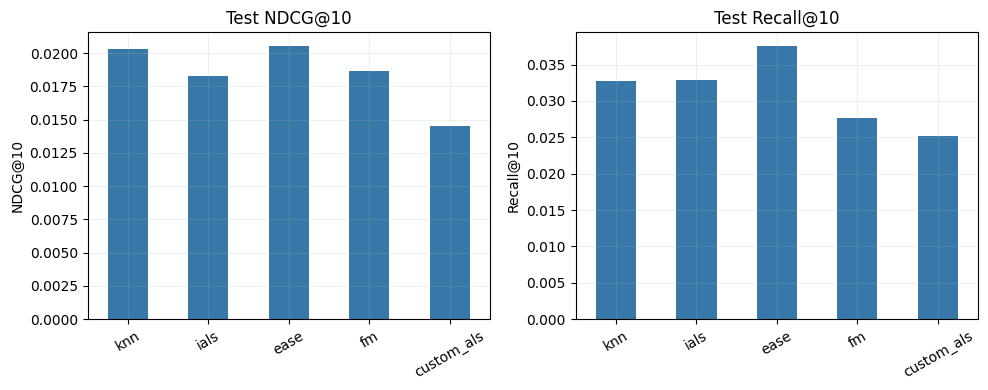

In [7]:
results, recommendations, per_user_ndcg, losses, test_users = run_test(bundle, CONFIG, selected_config)
print('Test users:', len(test_users))
display(results.sort_values('NDCG@10', ascending=False).reset_index(drop=True))
fig, axes = plt.subplots(1, 2, figsize=(10,4))
for ax, metric in zip(axes, ['NDCG@10', 'Recall@10']):
    results.set_index('model')[metric].plot.bar(ax=ax, color='#3878a8')
    ax.set(title=f'Test {metric}', xlabel='', ylabel=metric)
    ax.tick_params(axis='x', rotation=30)
fig.tight_layout()
plt.show()

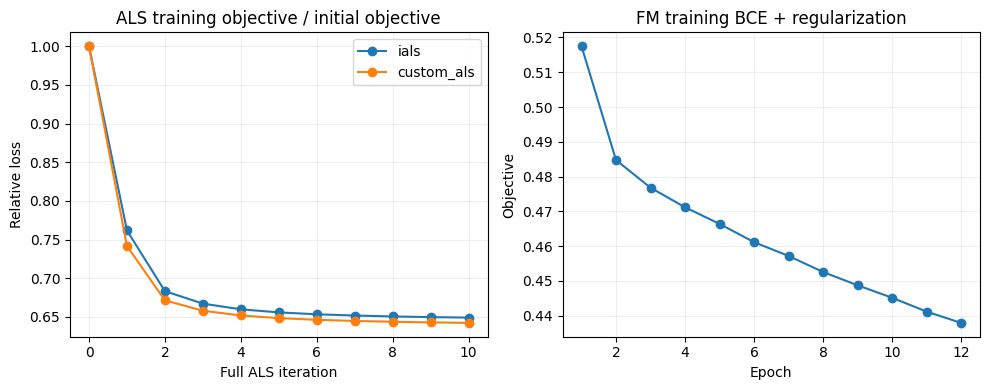

Custom ALS − iALS NDCG@10: -0.003717; paired bootstrap 95% CI [-0.006329, -0.001298]


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10,4))
for name in ['ials', 'custom_als']:
    curve = np.asarray(losses[name])
    axes[0].plot(np.arange(len(curve)), curve / curve[0], marker='o', label=name)
axes[0].set(title='ALS training objective / initial objective', xlabel='Full ALS iteration', ylabel='Relative loss')
axes[0].legend()
axes[1].plot(np.arange(1, len(losses['fm'])+1), losses['fm'], marker='o')
axes[1].set(title='FM training BCE + regularization', xlabel='Epoch', ylabel='Objective')
fig.tight_layout()
plt.show()
for name in ['ials', 'custom_als']:
    assert np.all(np.diff(losses[name]) <= 1e-5)
delta, interval = paired_bootstrap(per_user_ndcg['custom_als'], per_user_ndcg['ials'], seed=CONFIG['seed'])
print(f'Custom ALS − iALS NDCG@10: {delta:+.6f}; paired bootstrap 95% CI [{interval[0]:+.6f}, {interval[1]:+.6f}]')

### Пример персональных рекомендаций
Пользователь выбран фиксированным seed из test-когорты. Показываем историю, релевантные будущие товары и top-10 всех моделей; внешний reviewer ID не публикуется.

In [9]:
rng = np.random.default_rng(CONFIG['seed'])
position = int(rng.integers(len(test_users)))
user = int(test_users[position])
history = pd.concat([parts['train'], parts['validation']], ignore_index=True)
lookup = items[['title', 'brand', 'category']]
print('Internal user index:', user)
display(history[history.u.eq(user)][['i','rating','timestamp']].merge(
    lookup, left_on='i', right_index=True).sort_values('timestamp').drop(columns='timestamp'))
print('Relevant held-out items:')
display(parts['test'][parts['test'].u.eq(user) & parts['test'].rating.ge(4)][['i','rating']].merge(
    lookup, left_on='i', right_index=True))
example = pd.DataFrame({name: items.iloc[top[position]].title.to_numpy() for name, top in recommendations.items()},
                       index=np.arange(1,11))
example.index.name = 'rank'
with pd.option_context('display.max_colwidth', 65):
    display(example)
known = interaction_matrix(history, shape)
for name, top in recommendations.items():
    assert top.shape == (len(test_users), 10)
    assert all(len(set(row)) == 10 for row in top)
    assert all(not np.isin(row, known.indices[known.indptr[u]:known.indptr[u+1]]).any() for u, row in zip(test_users, top))
print('All recommendations: 10 unique unseen items per user.')

Internal user index: 1718


,i,rating,title,brand,category
24217,2715,4.0,Blueridge BR-163 Historic Series 000 Guitar,Blueridge,Steel-string Acoustics
25603,2053,2.0,"Yamaha GL1 Guitalele, Natural",Yamaha,General Accessories
36725,2878,5.0,12 Piece DRUM PRACTICE PADS - Silent Black Foa...,EDMBG,Practice Pads & Devices
39729,500,5.0,DrumDial Precision Drum Tuner,Drumdial,Tuning
39730,620,5.0,Vic Firth American Custom SD2 Bolero Drumsticks,Vic Firth,Drumsticks
39731,1355,5.0,Meinl Percussion Drum Stick Bag with Extra Out...,Meinl Percussion,"Drum Set Bags, Cases & Covers"
39732,3009,5.0,Promark Hickory DC51 Wood Tip drumstick,Promark,Drumsticks
43896,794,5.0,K & M Music Stand (15213.077.55),K & M,Stands
43897,3790,2.0,Protec Trumpet Liberty Symphonic Aluminum Wa W...,ProTec,Trumpet
51076,4449,2.0,Rechargeable Music Stand LED Light Clip-on 9 L...,Morcolor,Stand Lights


Relevant held-out items:


,i,rating,title,brand,category
3548,1519,4.0,Herco HE360 Guitar Humidifier,Herco,Cleaning & Care


,knn,ials,ease,fm,custom_als
rank,,,,,
1,Superior CD-1513 Deluxe Hardshell Parlor Acoustic Guitar Case,Vic Firth American Classic 5A Drum Sticks,Evans Acoustic Guitar Body (RF12D),Vic Firth American Classic 5A Drum Sticks,Vic Firth American Classic 5A Drum Sticks
2,Evans Acoustic Guitar Body (RF12D),RTOM MG4 Acoustic Guitar Case,RTOM MG4 Acoustic Guitar Case,"D'Addario EJ21 Nickel Wound Electric Guitar Strings, Jazz Lig...",RTOM MG4 Acoustic Guitar Case
3,Bach Trumpet Mouthpiece 3C,Promark T-RODS Thunder Rods,"Evans EQ Double Pedal Patch, Black Nylon",Elixir Strings 80/20 Bronze Acoustic Guitar Strings w POLYWEB...,"Evans EQ Double Pedal Patch, Black Nylon"
4,Denis Wick DW5504 Trumpet Straight Mute,"Evans EQ Double Pedal Patch, Black Nylon","Evans EMAD2 Clear Bass Drum Head, 20 Inch",Evans Acoustic Guitar Body (RF12D),Remo Ambassador Coated Drum Head - 16 Inch
5,K & M Music Stand (15240.000.55),Evans Acoustic Guitar Body (RF12D),Vic Firth American Classic 5A Drum Sticks,Vic Firth Kidsticks (KIDS),M-Audio SP-2 | Universal Sustain Pedal with Piano Style Actio...
6,RTOM MG4 Acoustic Guitar Case,Remo Ambassador Coated Drum Head - 16 Inch,"Evans Genera HD Dry Drum Head, 13 Inch",Zildjian 5A Nylon Black Dip Drumsticks,Evans Acoustic Guitar Body (RF12D)
7,"Herco HE185 Spitballs, Small, 18/Jar","Evans EMAD2 Clear Bass Drum Head, 20 Inch",Remo Ambassador Coated Drum Head - 16 Inch,Elixir Strings 80/20 Bronze Acoustic Guitar Strings w POLYWEB...,Promark T-RODS Thunder Rods
8,"Evans EMAD2 Clear Bass Drum Head, 20 Inch","Evans G2 Tompack, Clear, Fusion (10 inch, 12 inch, 14 inch)",Promark T-RODS Thunder Rods,"D'Addario EXL120+ Nickel Wound Electric Guitar Strings, Super...","Fender Clip-On Tuner FT-004 for Guitar, Ukulele, Bass, Violin..."
9,"Evans EQ Double Pedal Patch, Black Nylon","Evans Genera HD Dry Drum Head, 13 Inch",Evans EQ Pad Bass Drum Damper,10 Pairs USA Made 5B Wood Tip Drumsticks with Onstage Stick B...,"Evans EMAD2 Clear Bass Drum Head, 20 Inch"


All recommendations: 10 unique unseen items per user.


## 6. Выводы

In [10]:
ordered = results.sort_values('NDCG@10', ascending=False).reset_index(drop=True)
winner = ordered.iloc[0]
metadata_delta = float(fm_main['NDCG@10'] - fm_ablation['NDCG@10'])
custom_direction = 'выше' if delta > 0 else 'ниже'
metadata_direction = 'выше' if metadata_delta > 0 else 'ниже'
uncertain = 'Интервал включает ноль: устойчивое преимущество не подтверждено.' if interval[0] <= 0 <= interval[1] else 'Интервал не включает ноль для этой test-когорты.'
display(Markdown(
    f"- Лучший test NDCG@10: **{winner['model']}**, **{winner['NDCG@10']:.5f}**; Recall@10 **{winner['Recall@10']:.5f}**. "
    f"Выбранные настройки: `{winner['params']}`.\n"
    f"- Кастомный таргет: NDCG {custom_direction} базового iALS на **{abs(delta):.5f}**; "
    f"95% paired bootstrap CI **[{interval[0]:+.5f}, {interval[1]:+.5f}]**. {uncertain}\n"
    f"- FM с метаданными: validation NDCG {metadata_direction} ID-only на **{abs(metadata_delta):.5f}** при одинаковых настройках. "
    f"Это эффект выбранного набора признаков/регуляризации, не универсальное свойство метаданных."
))
print('Measured notebook seconds (cached downloads):', round(perf_counter()-START, 2))
print('Total fit seconds:', round(validation_results.fit_seconds.sum() + fm_ablation['fit_seconds'] + results.fit_seconds.sum(), 2))

- Лучший test NDCG@10: **ease**, **0.02054**; Recall@10 **0.03756**. Выбранные настройки: `{"regularization": 1000}`.
- Кастомный таргет: NDCG ниже базового iALS на **0.00372**; 95% paired bootstrap CI **[-0.00633, -0.00130]**. Интервал не включает ноль для этой test-когорты.
- FM с метаданными: validation NDCG выше ID-only на **0.00180** при одинаковых настройках. Это эффект выбранного набора признаков/регуляризации, не универсальное свойство метаданных.

Measured notebook seconds (cached downloads): 202.37
Total fit seconds: 153.99


На validation увеличение kNN до 150 соседей и shrinkage до 50 улучшило NDCG в проверенной сетке. Для EASE лучшим стало λ=1000. На test EASE опережает kNN по NDCG лишь на 0.000231; устойчивость этого малого разрыва отдельно не проверялась. kNN охватывает 56.48% каталога, EASE — 31.57%, FM — 4.85%: качество и разнообразие рекомендаций различаются.

Ограничения: одна категория и одно временное разбиение; усечённый train-каталог и warm-start не покрывают новых пользователей/товары. Исходная 5-core сформирована по всему периоду: есть смещение отбора по будущей активности. Отзывы не равны всем покупкам, неизвестные товары могут быть релевантны. Снимок метаданных не исторический. FM использует семплированные негативы; confidence iALS одинаков для всех наблюдений. Bootstrap оценивает разброс пользователей при фиксированных обученных моделях, не разброс переобучения/других временных окон. Результаты относятся к этому протоколу; причинный эффект отдельных компонентов кастомного сигнала не изолирован.

Для продолжения: несколько временных окон, разбор по активности и категориям, абляции центрирования/давности. Test после просмотра результатов не использовался для изменения настроек.